In [2]:
import pandas as pd

df = pd.read_csv("hotel_bookings.csv")

df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (119390, 32)

Column Names:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']

Missing Values:
hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights           

In [4]:
# Handle missing values

df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("Unknown")
df["agent"] = df["agent"].fillna(0)
df["company"] = df["company"].fillna(0)

# Check missing values again
print(df.isnull().sum())

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                     0
adr                         

In [5]:
df["Total Stay Nights"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)

df[["stays_in_weekend_nights", "stays_in_week_nights", "Total Stay Nights"]].head()


,stays_in_weekend_nights,stays_in_week_nights,Total Stay Nights
0,0,0,0
1,0,0,0
2,0,1,1
3,0,1,1
4,0,2,2


In [6]:
df["Total Guests"] = (
    df["adults"] +
    df["children"] +
    df["babies"]
)

df[["adults", "children", "babies", "Total Guests"]].head()

,adults,children,babies,Total Guests
0,2,0.0,0,2.0
1,2,0.0,0,2.0
2,1,0.0,0,1.0
3,1,0.0,0,1.0
4,2,0.0,0,2.0


In [7]:
def lead_time_band(days):
    if days <= 30:
        return "0-30 Days"
    elif days <= 90:
        return "31-90 Days"
    elif days <= 180:
        return "91-180 Days"
    else:
        return "180+ Days"

df["Lead Time Band"] = df["lead_time"].apply(lead_time_band)

df[["lead_time", "Lead Time Band"]].head(10)

,lead_time,Lead Time Band
0,342,180+ Days
1,737,180+ Days
2,7,0-30 Days
3,13,0-30 Days
4,14,0-30 Days
5,14,0-30 Days
6,0,0-30 Days
7,9,0-30 Days
8,85,31-90 Days
9,75,31-90 Days


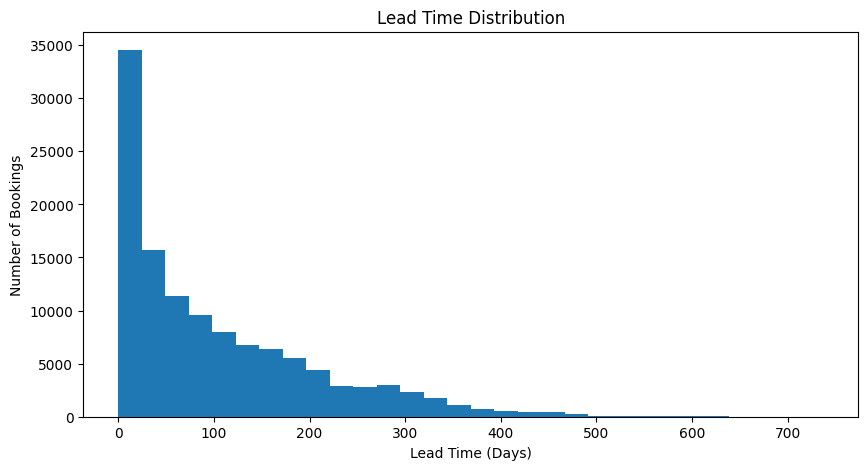

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df["lead_time"], bins=30)

plt.xlabel("Lead Time (Days)")
plt.ylabel("Number of Bookings")
plt.title("Lead Time Distribution")

plt.show()

In [10]:
# Calculate cancellation rate

total_bookings = len(df)
cancelled_bookings = df["is_canceled"].sum()

cancellation_rate = (cancelled_bookings / total_bookings) * 100

print("Total Bookings:", total_bookings)
print("Cancelled Bookings:", cancelled_bookings)
print("Cancellation Rate: {:.2f}%".format(cancellation_rate))

Total Bookings: 119390
Cancelled Bookings: 44224
Cancellation Rate: 37.04%


In [11]:
# Calculate Average Daily Rate (ADR)

avg_adr = df["adr"].mean()

print("Average Daily Rate (ADR): {:.2f}".format(avg_adr))



Average Daily Rate (ADR): 101.83


In [12]:
# Calculate Booking Revenue

df["Booking Revenue"] = df["adr"] * df["Total Stay Nights"]

total_booking_revenue = df["Booking Revenue"].sum()

print("Total Booking Revenue: {:.2f}".format(total_booking_revenue))

Total Booking Revenue: 42723497.53


In [13]:
# Calculate Revenue Lost to Cancellations

cancelled_revenue = df.loc[
    df["is_canceled"] == 1,
    "Booking Revenue"
].sum()

print("Revenue Lost to Cancellations: {:.2f}".format(cancelled_revenue))

Revenue Lost to Cancellations: 16727237.12


In [14]:
# Cancellation rate by customer type

customer_cancellation = (
    df.groupby("customer_type")["is_canceled"]
    .mean() * 100
)

print(customer_cancellation)

customer_type
Contract           30.961727
Group              10.225303
Transient          40.746320
Transient-Party    25.429868
Name: is_canceled, dtype: float64


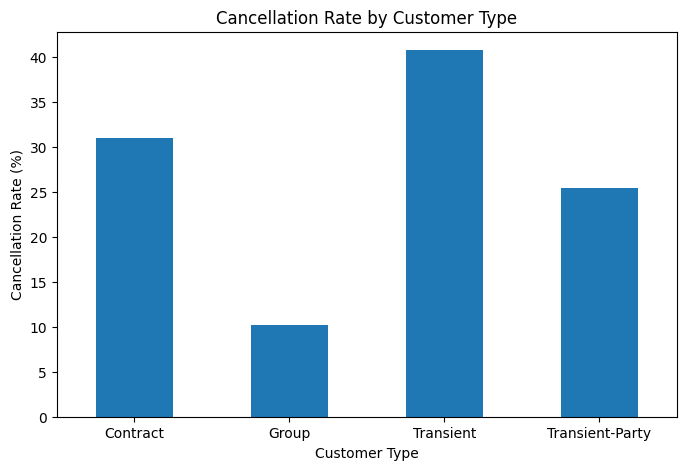

In [15]:
customer_cancellation.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Customer Type")
plt.ylabel("Cancellation Rate (%)")
plt.title("Cancellation Rate by Customer Type")
plt.xticks(rotation=0)
plt.show()

In [16]:
# Cancellation rate by Lead Time Band

lead_time_cancellation = (
    df.groupby("Lead Time Band")["is_canceled"]
    .mean() * 100
)

print(lead_time_cancellation)

Lead Time Band
0-30 Days      18.563013
180+ Days      57.010368
31-90 Days     37.698372
91-180 Days    44.710466
Name: is_canceled, dtype: float64


In [17]:
# Cancellation rate by hotel type

hotel_cancellation = (
    df.groupby("hotel")["is_canceled"]
    .mean() * 100
)

print(hotel_cancellation)

hotel
City Hotel      41.726963
Resort Hotel    27.763355
Name: is_canceled, dtype: float64


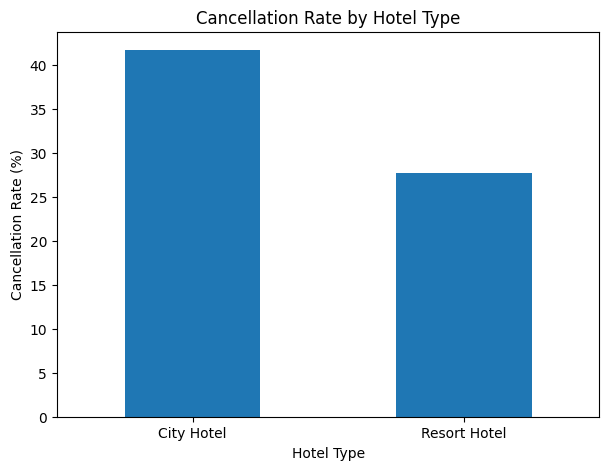

In [18]:
hotel_cancellation.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.title("Cancellation Rate by Hotel Type")
plt.xticks(rotation=0)
plt.show()

In [19]:
# Cancellation rate by month

monthly_cancellation = (
    df.groupby("arrival_date_month")["is_canceled"]
    .mean() * 100
)

print(monthly_cancellation)

arrival_date_month
April        40.797186
August       37.753117
December     34.970501
February     33.415964
January      30.477315
July         37.453598
June         41.457172
March        32.152338
May          39.665847
November     31.233441
October      38.046595
September    39.170156
Name: is_canceled, dtype: float64


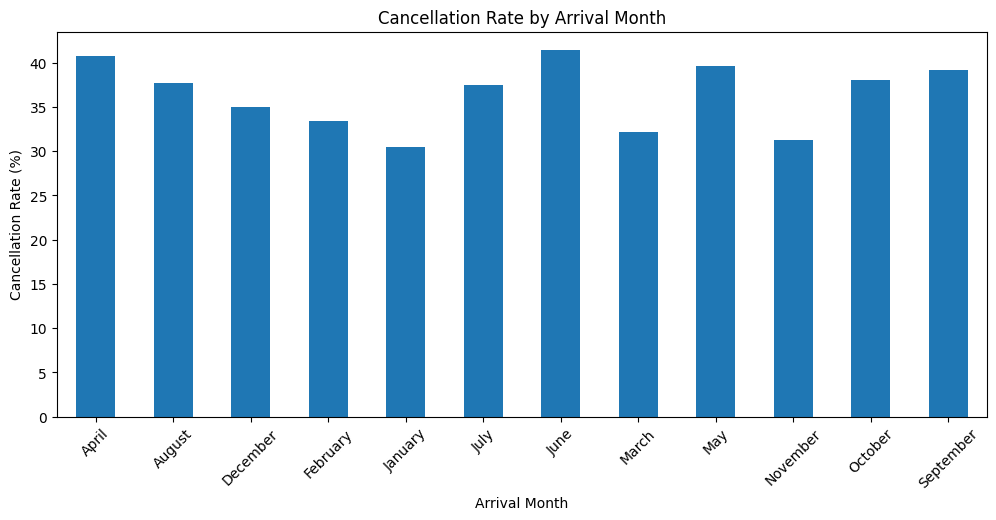

In [20]:
monthly_cancellation.plot(
    kind="bar",
    figsize=(12, 5)
)

plt.xlabel("Arrival Month")
plt.ylabel("Cancellation Rate (%)")
plt.title("Cancellation Rate by Arrival Month")
plt.xticks(rotation=45)
plt.show()

In [21]:
# Cancellation rate by Total Stay Nights

stay_cancellation = (
    df.groupby("Total Stay Nights")["is_canceled"]
    .mean() * 100
)

print(stay_cancellation.head(15))

Total Stay Nights
0      4.895105
1     25.076118
2     44.000289
3     41.922736
4     36.575965
5     34.211202
6     39.797770
7     34.303871
8     37.984496
9     37.217598
10    31.255487
11    30.303030
12    43.946188
13    35.915493
14    28.056769
Name: is_canceled, dtype: float64


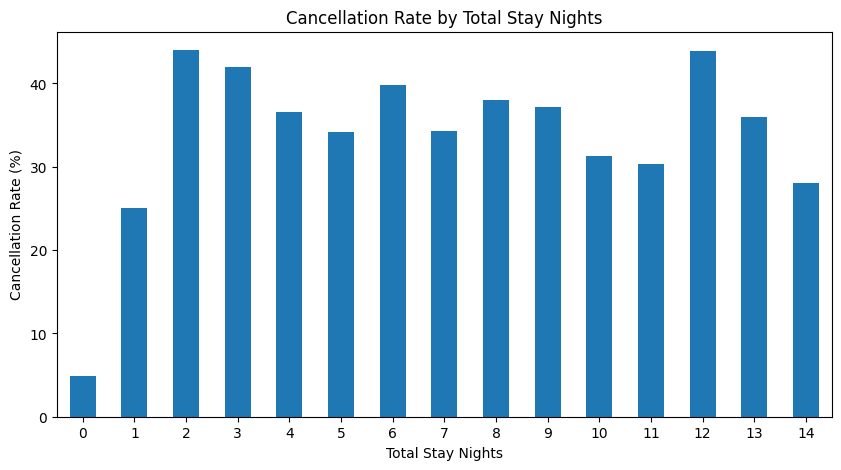

In [22]:
stay_cancellation.head(15).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.xlabel("Total Stay Nights")
plt.ylabel("Cancellation Rate (%)")
plt.title("Cancellation Rate by Total Stay Nights")
plt.xticks(rotation=0)
plt.show()

In [23]:
# Cancellation rate by Total Guests

guest_cancellation = (
    df.groupby("Total Guests")["is_canceled"]
    .mean() * 100
)

print(guest_cancellation)

Total Guests
0.0      13.888889
1.0      29.028830
2.0      39.697261
3.0      32.177227
4.0      41.893612
5.0      24.817518
6.0     100.000000
10.0     50.000000
12.0     50.000000
20.0    100.000000
26.0    100.000000
27.0    100.000000
40.0    100.000000
50.0    100.000000
55.0    100.000000
Name: is_canceled, dtype: float64


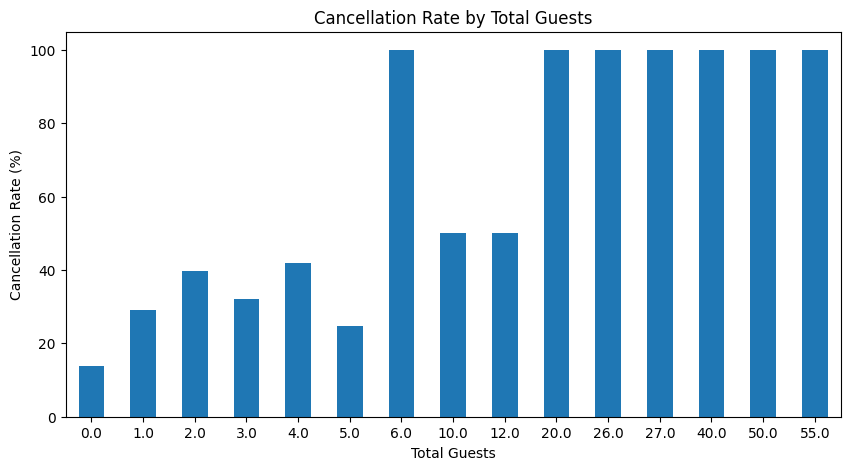

In [24]:
guest_cancellation.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.xlabel("Total Guests")
plt.ylabel("Cancellation Rate (%)")
plt.title("Cancellation Rate by Total Guests")
plt.xticks(rotation=0)
plt.show()

In [25]:
# Final KPI Summary

kpi_summary = {
    "Total Bookings": len(df),
    "Cancelled Bookings": int(df["is_canceled"].sum()),
    "Cancellation Rate (%)": round(cancellation_rate, 2),
    "Average Daily Rate (ADR)": round(avg_adr, 2),
    "Total Booking Revenue": round(total_booking_revenue, 2),
    "Revenue Lost to Cancellations": round(cancelled_revenue, 2)
}

kpi_df = pd.DataFrame(
    kpi_summary.items(),
    columns=["KPI", "Value"]
)

kpi_df

,KPI,Value
0,Total Bookings,119390.00
1,Cancelled Bookings,44224.00
2,Cancellation Rate (%),37.04
3,Average Daily Rate (ADR),101.83
4,Total Booking Revenue,42723497.53
5,Revenue Lost to Cancellations,16727237.12


In [26]:
# Find highest cancellation risk

highest_customer_type = customer_cancellation.idxmax()
highest_customer_rate = customer_cancellation.max()

highest_lead_band = lead_time_cancellation.idxmax()
highest_lead_rate = lead_time_cancellation.max()

print("Highest Cancellation Customer Type:")
print(highest_customer_type, "-", round(highest_customer_rate, 2), "%")

print("\nHighest Cancellation Lead Time Band:")
print(highest_lead_band, "-", round(highest_lead_rate, 2), "%")

Highest Cancellation Customer Type:
Transient - 40.75 %

Highest Cancellation Lead Time Band:
180+ Days - 57.01 %


In [27]:
# Final Findings

print("========== HOTEL BOOKING & CANCELLATION ANALYSIS ==========\n")

print("1. Overall Cancellation:")
print(f"   Cancellation Rate: {cancellation_rate:.2f}%")

print("\n2. Customer Type:")
print(f"   Highest cancellation rate: {highest_customer_type}")
print(f"   Cancellation rate: {highest_customer_rate:.2f}%")

print("\n3. Lead Time:")
print(f"   Highest cancellation band: {highest_lead_band}")
print(f"   Cancellation rate: {highest_lead_rate:.2f}%")

print("\n4. Revenue:")
print(f"   Total Booking Revenue: {total_booking_revenue:.2f}")
print(f"   Revenue Lost to Cancellations: {cancelled_revenue:.2f}")

print("\n5. Average Daily Rate:")
print(f"   Average ADR: {avg_adr:.2f}")

========== HOTEL BOOKING & CANCELLATION ANALYSIS ==========

1. Overall Cancellation:
   Cancellation Rate: 37.04%

2. Customer Type:
   Highest cancellation rate: Transient
   Cancellation rate: 40.75%

3. Lead Time:
   Highest cancellation band: 180+ Days
   Cancellation rate: 57.01%

4. Revenue:
   Total Booking Revenue: 42723497.53
   Revenue Lost to Cancellations: 16727237.12

5. Average Daily Rate:
   Average ADR: 101.83
